# 09 · Phase 04 · Milestone 1 — scientific validation (viewer)

**Authored 2026-10-11, NOT executed.** This notebook only **loads saved outputs** — all computation runs from the command line so the heavy steps are cached and reproducible:

```
python -m pytest tests/test_phase04_m1.py tests/test_polars2_compat.py -q
python -m nflbdb.research.phase04 --only Q
python -m nflbdb.research.phase04 --only B --sample-athletes 120      # smoke → */phase_04/_sample
python -m nflbdb.research.phase04 --only B
python -m nflbdb.research.phase04 --only C1
python -m nflbdb.research.phase04 --only V
python -m nflbdb.research.phase04 --check
python -m nflbdb.research.phase04 --report
```

Sections follow *Question → Population → Method → Results → Evidence → Figures → Interpretation → Limitations → Decision*. Interpretation cells stay empty until the numbers have been reviewed.

In [1]:
from IPython.display import Image, Markdown, display
import polars as pl

from nflbdb.data.config import Phase01Config, configure_runtime
from nflbdb.research.studies.store import StudyStore
from nflbdb.research.phase04 import events as c1, quality_eligibility as q, smoothing as b, validation_registry as v
from nflbdb.research.phase04 import annotation_design as ad

SAMPLED = False          # True → read the bounded smoke run (*/phase_04/_sample)
cfg = Phase01Config.load(); configure_runtime(cfg)
s4 = StudyStore(cfg, sampled=SAMPLED, phase="phase_04")

def table(contract, store=s4):
    try:
        return store.read(contract)
    except FileNotFoundError as e:
        display(Markdown(f"**missing:** {e}")); return None

def figures(study):
    d = s4.figure_dir(study)
    for p in sorted(d.glob("*.png")) if d.is_dir() else []:
        display(Markdown(f"`{cfg.paths.rel(p)}`")); display(Image(filename=str(p), width=1000))

pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(16)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\data\config.py:264: UserWarning: polars was imported before configure_runtime(); POLARS_MAX_THREADS will not apply to this process. Restart the kernel and call configure_runtime() first.
  warnings.warn(


polars.config.Config

## Q · Structural vs signal quality and athlete eligibility (Study 1.1)
**Question.** Are structural defects and signal defects the same trajectories, and how many athletes survive each filter? **Population.** All Combine attempts + deterministic NFL sample (A ∩ A3).

domain,stratum,n_trajectories,n_athletes,n_both,n_structural_only,n_signal_only,n_neither,kappa,ci_lower,ci_upper,result_status
str,str,i64,i64,i64,i64,i64,i64,f64,f64,f64,str
"""combine""","""FORTY_YARD_DASH""",793,418,7,1,51,734,0.197899,0.079785,0.323745,"""exploratory"""
"""combine""","""SKILL_DRILLS_DL""",1007,114,8,3,91,905,0.128315,0.050753,0.210624,"""exploratory"""
"""combine""","""SHORT_SHUTTLE""",223,170,3,0,15,205,0.268852,0.0,0.457967,"""exploratory"""
"""combine""","""THREE_CONE_DRILL""",203,160,2,1,18,182,0.152121,-0.009723,0.364197,"""exploratory"""
"""combine""","""SKILL_DRILLS_DB""",1170,122,11,1,81,1077,0.196967,0.085048,0.309191,"""exploratory"""
"""combine""","""SKILL_DRILLS_TE""",438,42,5,0,36,397,0.201135,0.057616,0.328843,"""exploratory"""
"""combine""","""SKILL_DRILLS_WR""",1529,107,11,5,115,1398,0.138939,0.041074,0.207283,"""exploratory"""
"""combine""","""SKILL_DRILLS_OL""",910,121,8,2,72,828,0.161395,0.044426,0.273002,"""exploratory"""
"""combine""","""SKILL_DRILLS_LB""",37,4,1,0,2,34,null,null,null,"""insufficient_data"""


domain,stratum,drill,scenario,scenario_order,n_trajectories,n_athletes_any,n_athletes_repeat,share_trajectories,share_athletes_any,share_athletes_repeat
str,str,str,str,i64,i64,i64,i64,f64,f64,f64
"""combine""","""FORTY_YARD_DASH""","""FORTY_YARD_DASH""","""S0 all""",0,793,418,375,1.0,1.0,1.0
"""combine""","""FORTY_YARD_DASH""","""FORTY_YARD_DASH""","""S1 structural pass""",1,785,416,369,0.989912,0.995215,0.984
"""combine""","""FORTY_YARD_DASH""","""FORTY_YARD_DASH""","""S2 + signal pass""",2,734,401,333,0.925599,0.95933,0.888
"""combine""","""FORTY_YARD_DASH""","""FORTY_YARD_DASH""","""S3 + no boundary peak""",3,632,378,254,0.796974,0.904306,0.677333
"""combine""","""SHORT_SHUTTLE""","""SHORT_SHUTTLE""","""S0 all""",0,223,170,42,1.0,1.0,1.0
"""combine""","""SHORT_SHUTTLE""","""SHORT_SHUTTLE""","""S1 structural pass""",1,220,168,41,0.986547,0.988235,0.97619
"""combine""","""SHORT_SHUTTLE""","""SHORT_SHUTTLE""","""S2 + signal pass""",2,205,156,39,0.919283,0.917647,0.928571
"""combine""","""SHORT_SHUTTLE""","""SHORT_SHUTTLE""","""S3 + no boundary peak""",3,203,155,38,0.910314,0.911765,0.904762
"""combine""","""THREE_CONE_DRILL""","""THREE_CONE_DRILL""","""S0 all""",0,203,160,38,1.0,1.0,1.0


`reports/figures/phase_04/Q_quality_eligibility/Q_01_flag_rates_by_stratum.png`

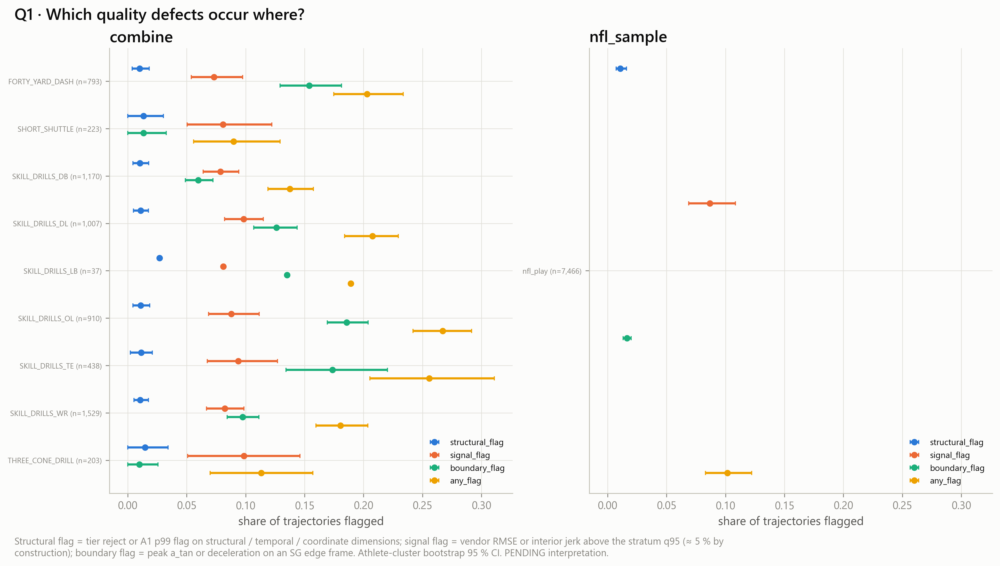

`reports/figures/phase_04/Q_quality_eligibility/Q_02_structural_vs_signal.png`

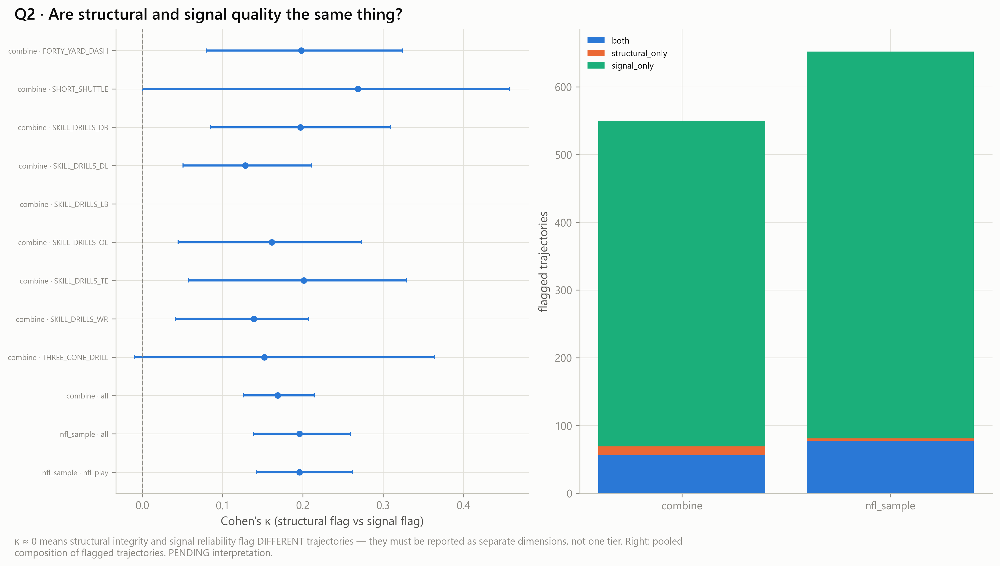

`reports/figures/phase_04/Q_quality_eligibility/Q_03_athlete_eligibility.png`

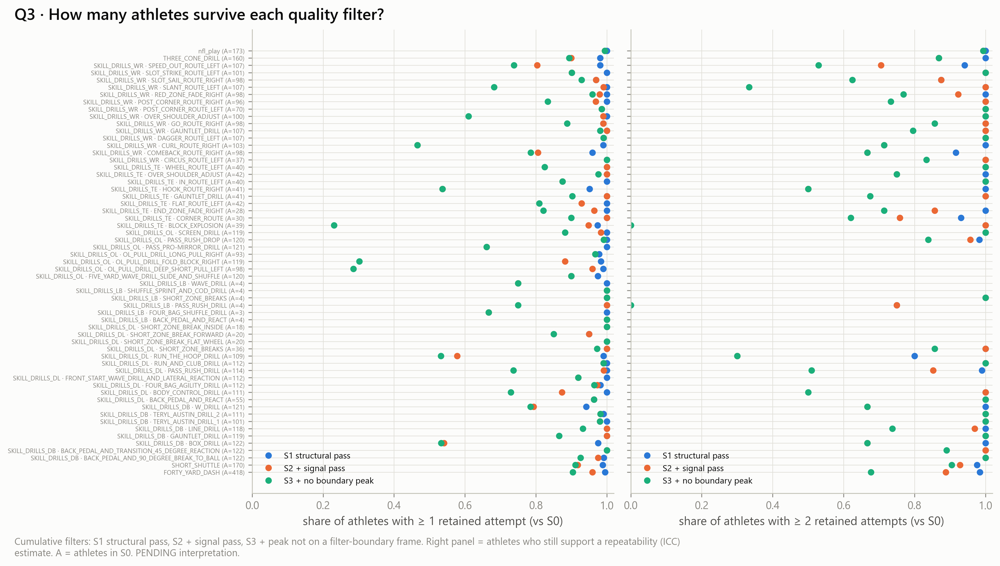

`reports/figures/phase_04/Q_quality_eligibility/Q_04_flags_by_cohort_position.png`

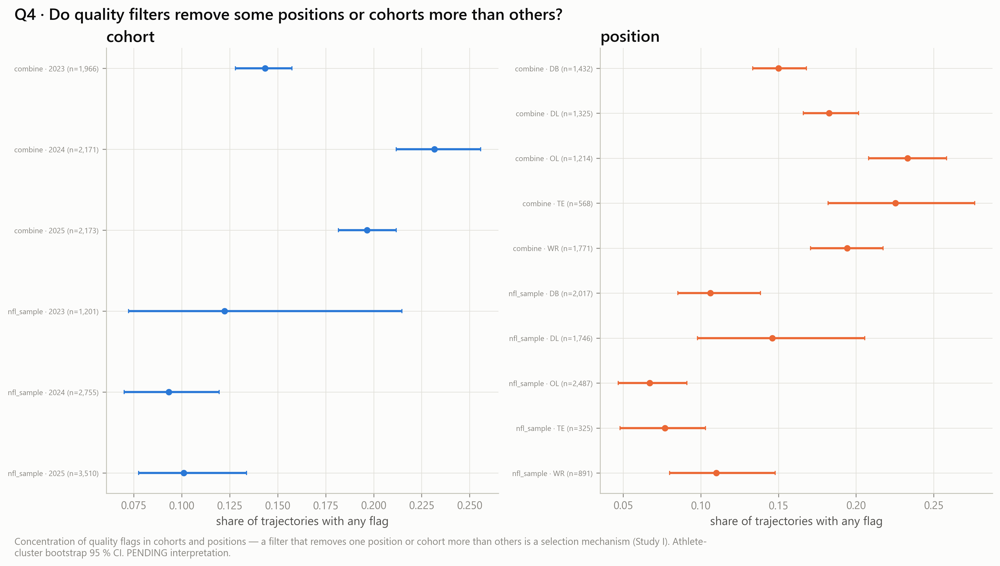

In [2]:
agree = table(q.AGREE); display(agree)
elig = table(q.ELIG)
if elig is not None:
    display(elig.filter(pl.col("drill").is_in(["FORTY_YARD_DASH", "SHORT_SHUTTLE", "THREE_CONE_DRILL", "nfl_play"])))
figures("Q")

**Interpretation (Q):** _to write after review._  
**Decision (Q):** _which filter scenario defines the research population for Milestone 2?_

## B · Smoothing robustness (Study 1.2)
**Question.** Which features keep athlete ranks and magnitudes across SG settings, and is repeatability setting-independent?

domain,drill,feature,level,rho_min,rho_lower_min,overlap_min,rel_diff_max
str,str,str,str,f64,f64,f64,f64
"""combine""","""FORTY_YARD_DASH""","""n_acceleration""","""athlete""",0.236028,0.192134,0.666667,0.0
"""combine""","""FORTY_YARD_DASH""","""rate_reversal_per_s""","""athlete""",0.666133,0.296821,0.904762,0.0
"""combine""","""FORTY_YARD_DASH""","""n_reversal""","""athlete""",0.664785,0.363333,0.928571,0.0
"""combine""","""FORTY_YARD_DASH""","""n_turn""","""athlete""",0.704559,0.448823,0.952381,1.0
"""combine""","""FORTY_YARD_DASH""","""rate_turn_per_s""","""athlete""",0.704559,0.573185,0.952381,1.0
"""combine""","""FORTY_YARD_DASH""","""p95_decel""","""athlete""",0.67671,0.617194,0.5,0.874982
"""combine""","""FORTY_YARD_DASH""","""peak_decel_interior""","""athlete""",0.727284,0.667998,0.571429,1.4
"""combine""","""FORTY_YARD_DASH""","""peak_decel""","""athlete""",0.724715,0.669752,0.761905,1.25
"""combine""","""FORTY_YARD_DASH""","""peak_abs_yaw_rate""","""athlete""",0.803513,0.760754,0.619048,0.237942


feature,sg5p2,sg7p2,sg9p2,sg11p3
str,f64,f64,f64,f64
"""peak_speed""",0.984164,0.984992,0.985083,0.984782
"""peak_speed_interior""",0.985424,0.986123,0.986811,0.985483
"""p95_speed""",0.986569,0.986741,0.986808,0.986261
"""path_smooth_yds""",0.305876,0.30607,0.306441,0.307007
"""peak_a_tan""",0.479296,0.506571,0.513278,0.412109
"""peak_a_tan_interior""",0.479296,0.506571,0.513278,0.533609
"""p95_a_tan""",0.512902,0.502175,0.510123,0.4658
"""peak_decel""",0.236089,0.174965,0.172571,0.230822
"""peak_decel_interior""",0.294442,0.230405,0.305944,0.370186


`reports/figures/phase_04/B_smoothing/B_01_sensitivity_heatmap.png`

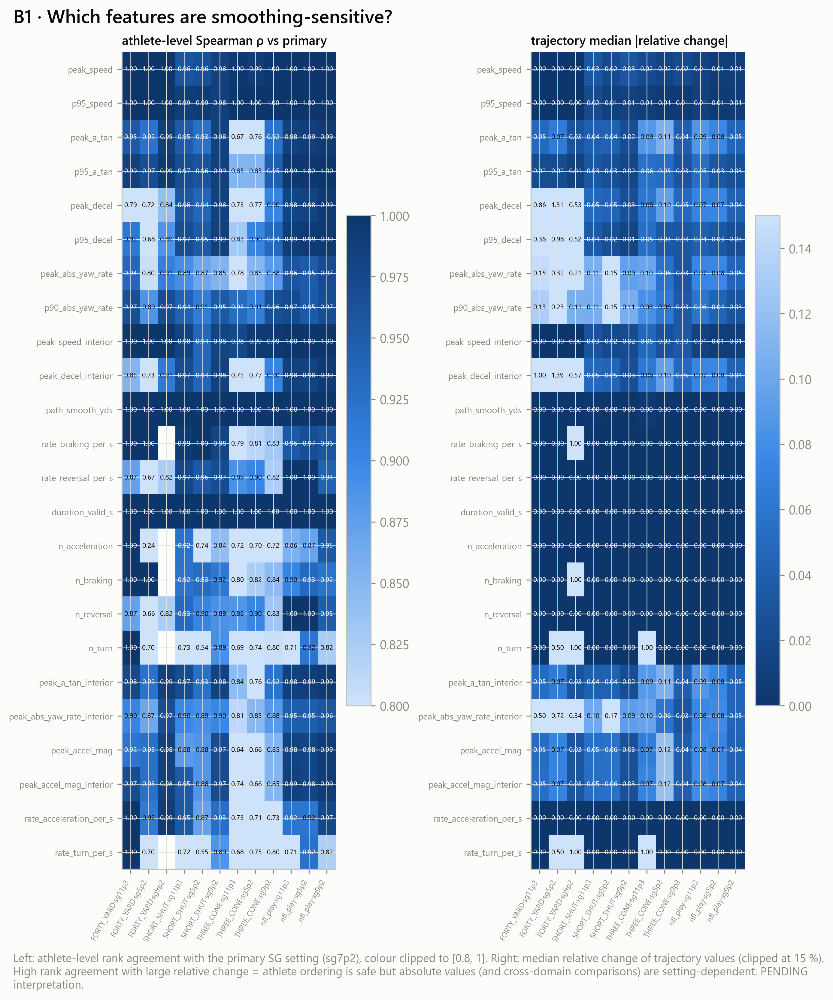

`reports/figures/phase_04/B_smoothing/B_02_bland_altman.png`

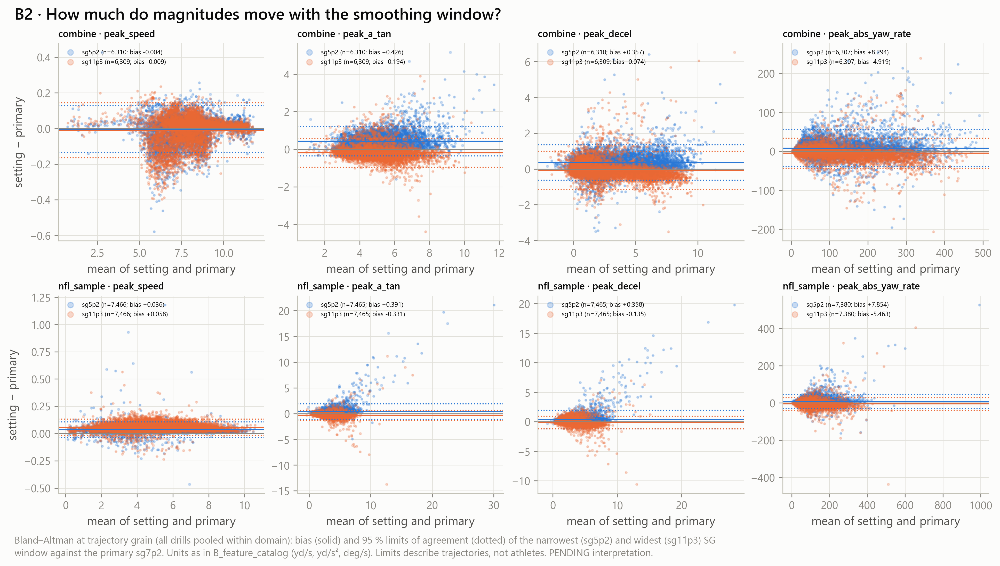

`reports/figures/phase_04/B_smoothing/B_03_rank_change_ecdf.png`

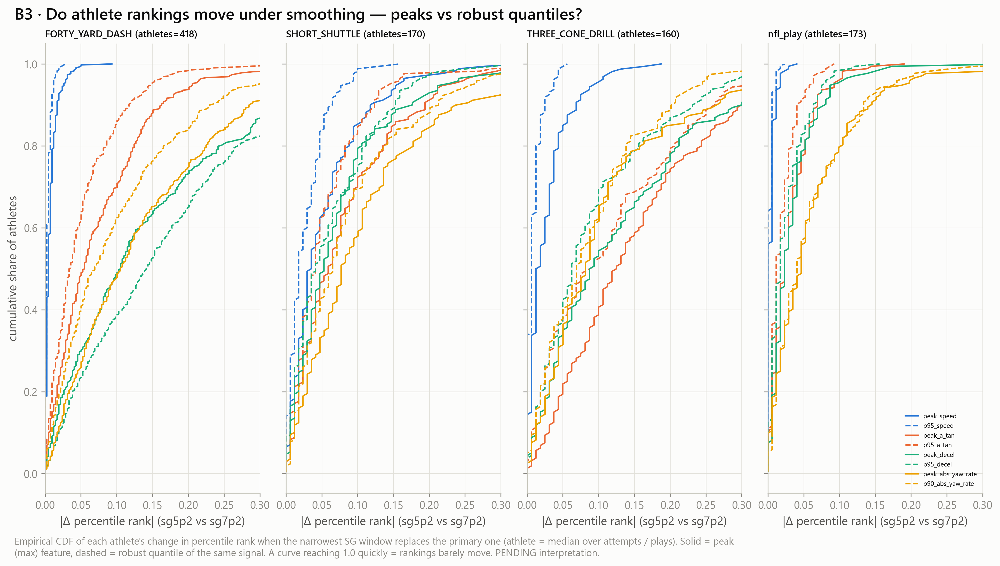

`reports/figures/phase_04/B_smoothing/B_04_top_decile_overlap.png`

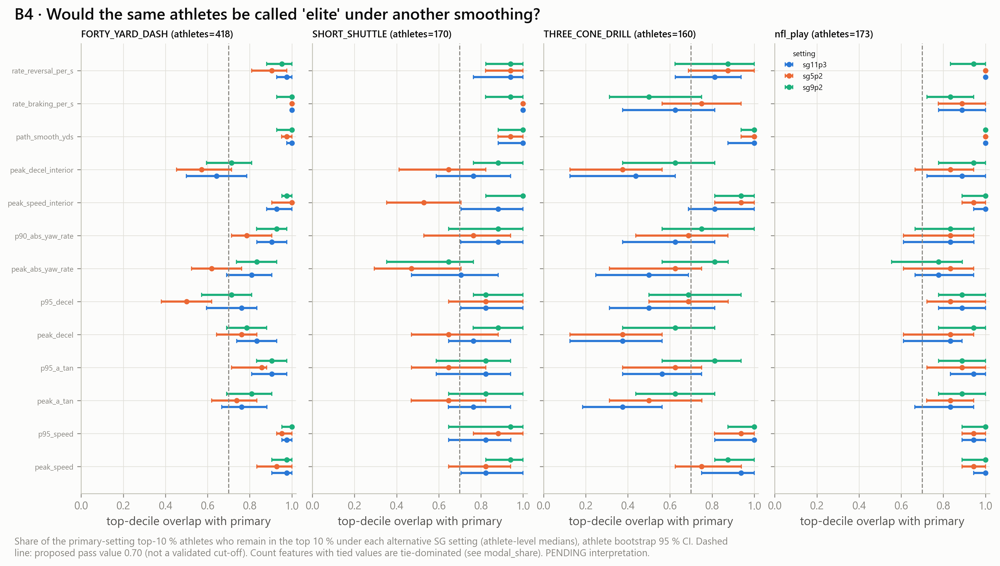

`reports/figures/phase_04/B_smoothing/B_05_variance_share.png`

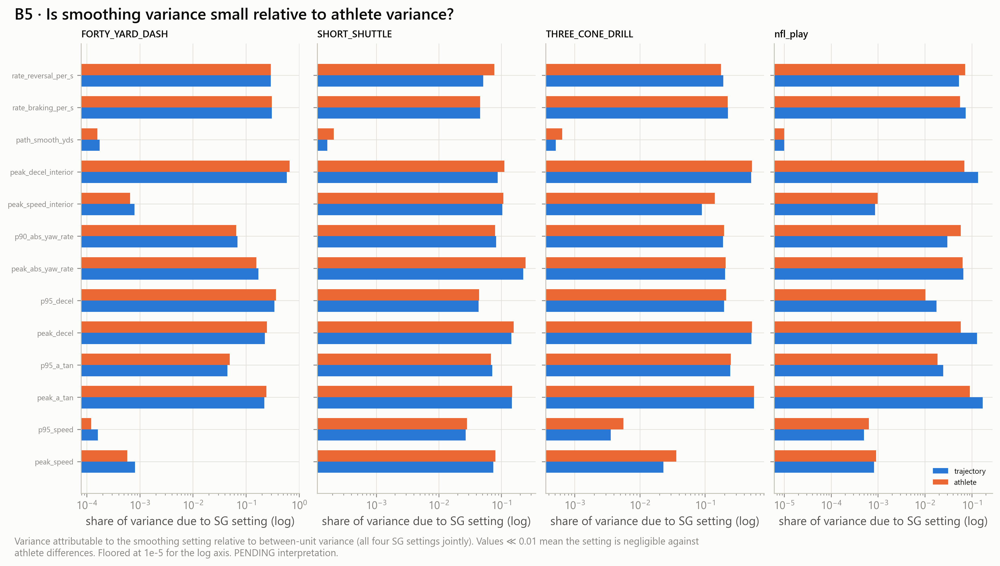

`reports/figures/phase_04/B_smoothing/B_06_icc_by_setting.png`

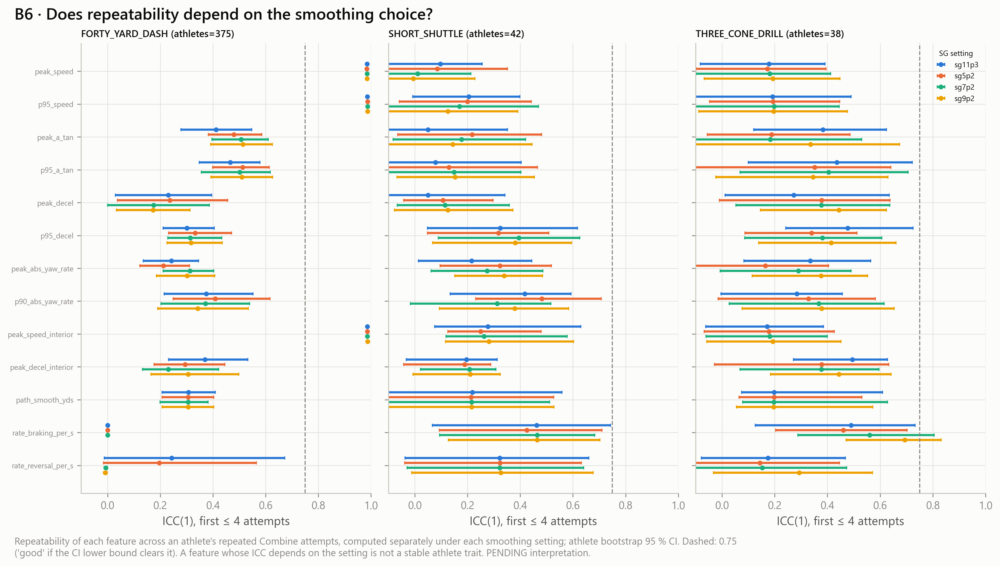

`reports/figures/phase_04/B_smoothing/B_07_cohort_position_robustness.png`

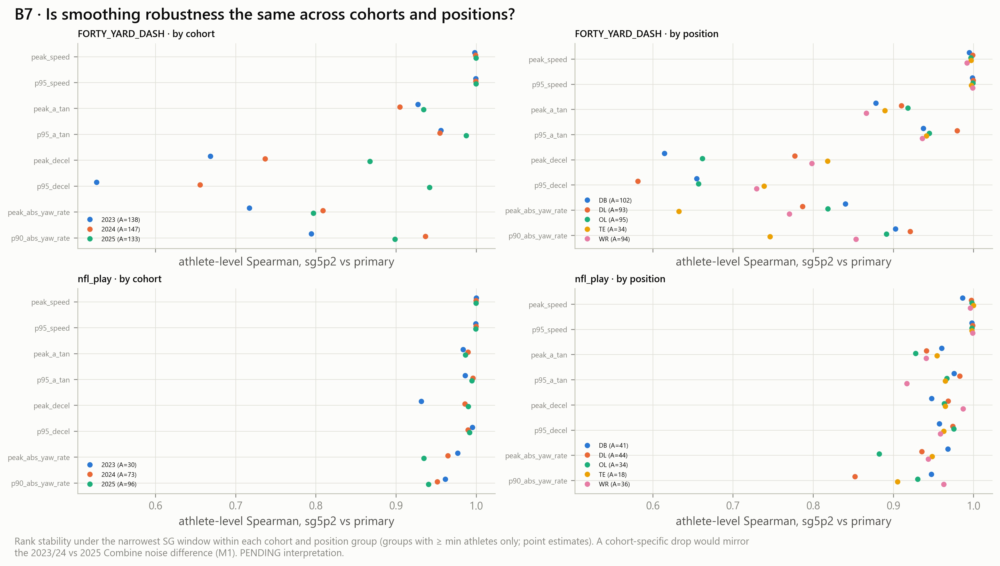

`reports/figures/phase_04/B_smoothing/B_08_vendor_residual_vs_speed.png`

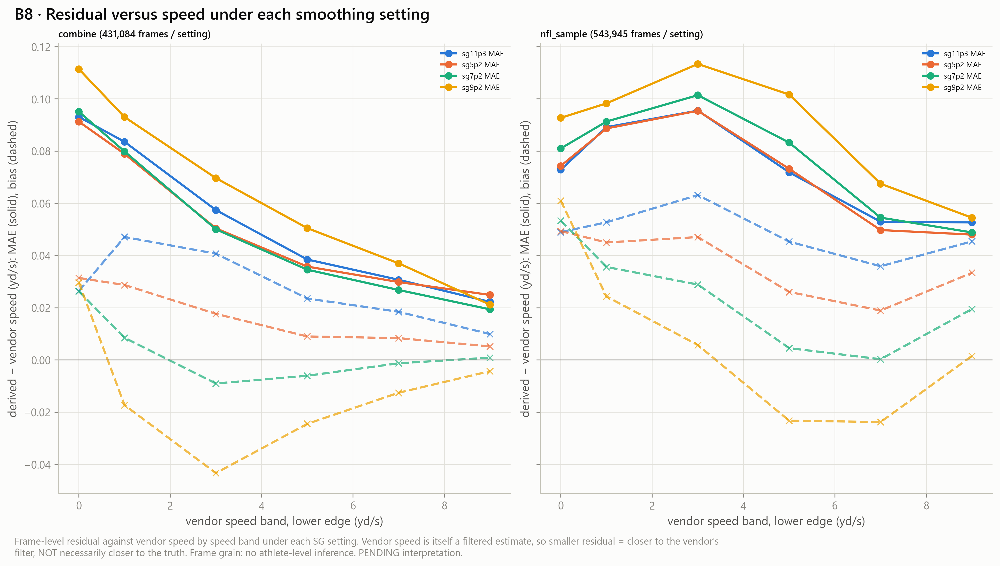

`reports/figures/phase_04/B_smoothing/B_09_example_signals.png`

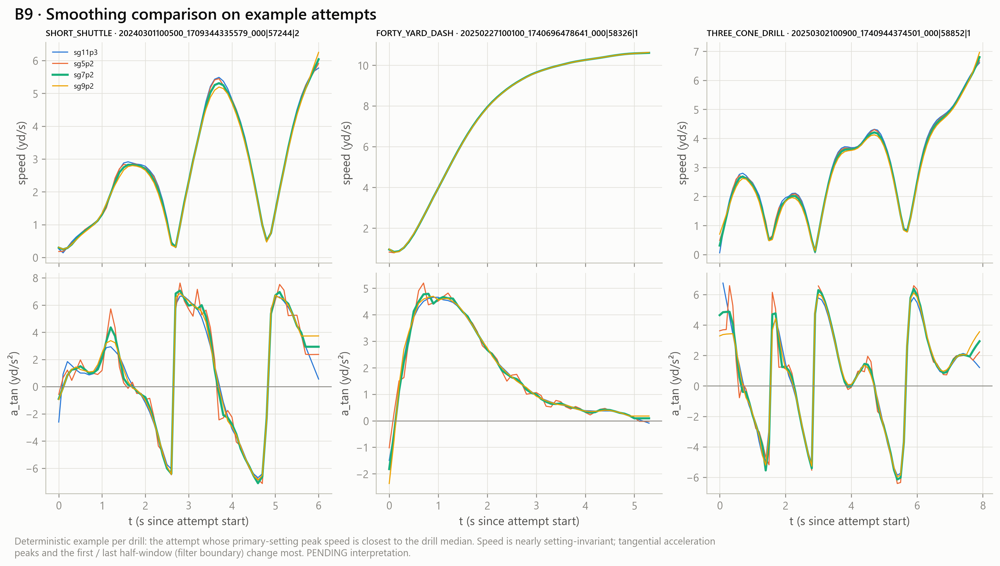

In [3]:
ag = table(b.AGREE)
if ag is not None:
    worst = (ag.filter(pl.col("drill").is_in(["FORTY_YARD_DASH", "SHORT_SHUTTLE", "THREE_CONE_DRILL", "nfl_play"]))
               .group_by("domain", "drill", "feature", "level")
               .agg(pl.col("spearman").min().alias("rho_min"), pl.col("spearman_lower").min().alias("rho_lower_min"),
                    pl.col("top_overlap").min().alias("overlap_min"), pl.col("median_rel_diff").max().alias("rel_diff_max"))
               .sort("domain", "drill", "level", "rho_lower_min"))
    display(worst.filter(pl.col("level") == "athlete"))
rep = table(b.REPEAT)
if rep is not None:
    display(rep.filter(pl.col("drill") == "FORTY_YARD_DASH").pivot(on="smoothing", index="feature", values="icc1"))
figures("B")

**Interpretation (B):** _to write after review — in particular: do `peak_speed_interior` / `p95_speed` resolve the A3 boundary concentration without losing repeatability?_

## C1 · Event-detector sensitivity (Study 1.3, consistency)
**Question.** Do event rates and individual events survive rule and smoothing changes? (Consistency, not accuracy.)

domain,event_type,default,lenient,strict
str,str,f64,f64,f64
"""combine""","""acceleration""",0.250177,0.313597,0.159478
"""combine""","""braking""",0.090259,0.134866,0.041313
"""combine""","""reversal""",0.065624,0.070913,0.053144
"""combine""","""turn""",0.050175,0.157321,0.003132
"""nfl_sample""","""acceleration""",0.123427,0.200749,0.05664
"""nfl_sample""","""braking""",0.080244,0.143079,0.0323
"""nfl_sample""","""reversal""",0.04254,0.053588,0.021141
"""nfl_sample""","""turn""",0.021546,0.10793,0.000533


drill,event_type,rule:lenient,rule:strict,sg:sg5p2,sg:sg9p2,sg:sg11p3
str,str,f64,f64,f64,f64,f64
"""SHORT_SHUTTLE""","""braking""",0.968463,0.802116,0.998324,0.978149,0.994161
"""SHORT_SHUTTLE""","""acceleration""",0.929045,0.684632,0.870764,0.925219,0.952466
"""SHORT_SHUTTLE""","""turn""",0.345229,0.447182,0.547134,0.886279,0.724605
"""SHORT_SHUTTLE""","""reversal""",0.939583,0.730062,0.954395,0.969973,0.974488
"""THREE_CONE_DRILL""","""braking""",0.364564,0.169424,0.814222,0.829587,0.786925
"""THREE_CONE_DRILL""","""acceleration""",0.344075,0.38011,0.714797,0.730926,0.734061
"""THREE_CONE_DRILL""","""turn""",0.288983,null,0.743275,0.795966,0.675961
"""THREE_CONE_DRILL""","""reversal""",0.739049,0.380392,0.896453,0.834547,0.883423
"""nfl_play""","""braking""",0.774795,0.890171,0.975078,0.969019,0.96955


`reports/figures/phase_04/C1_event_sensitivity/C1_01_rates_by_rule.png`

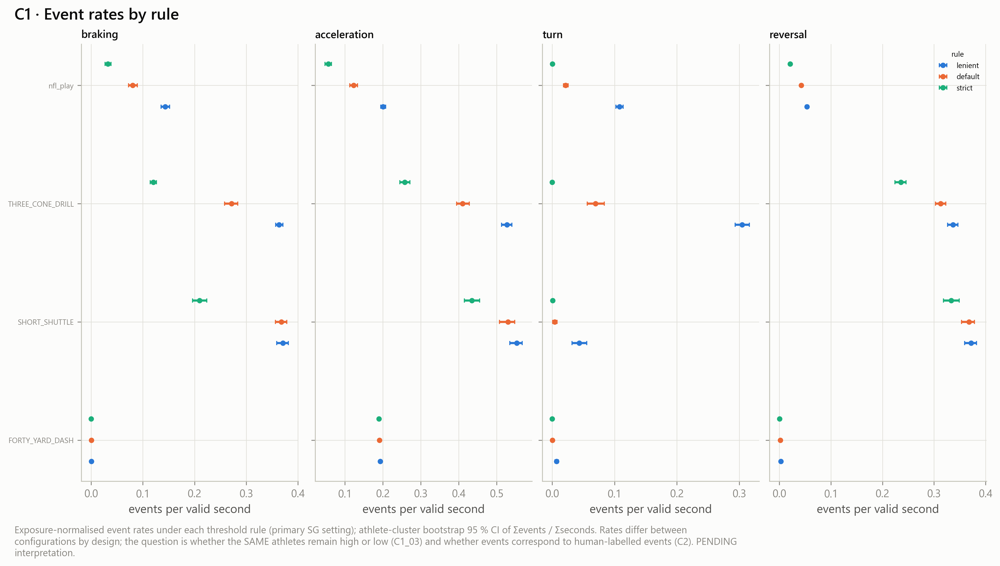

`reports/figures/phase_04/C1_event_sensitivity/C1_02_rates_by_smoothing.png`

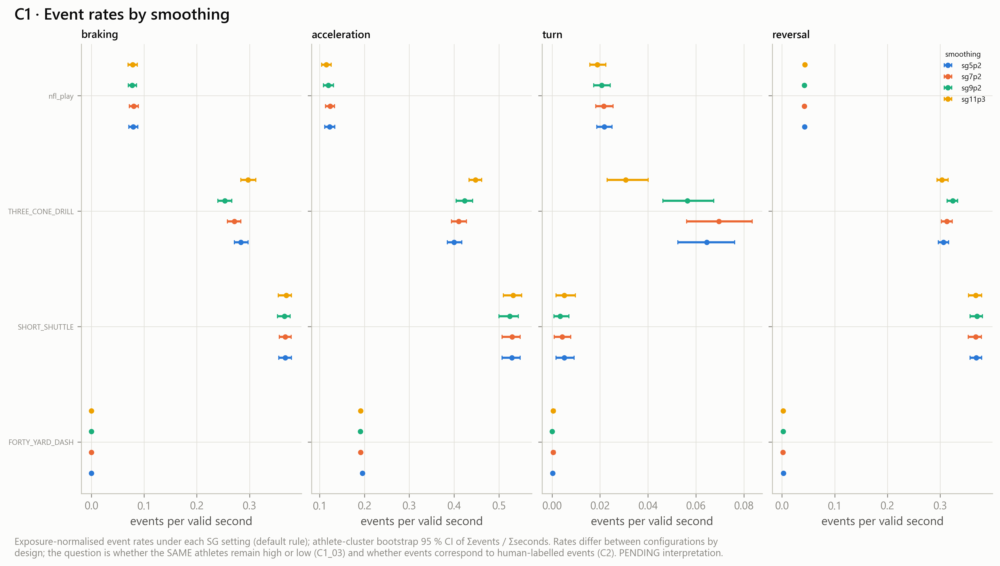

`reports/figures/phase_04/C1_event_sensitivity/C1_03_rate_stability.png`

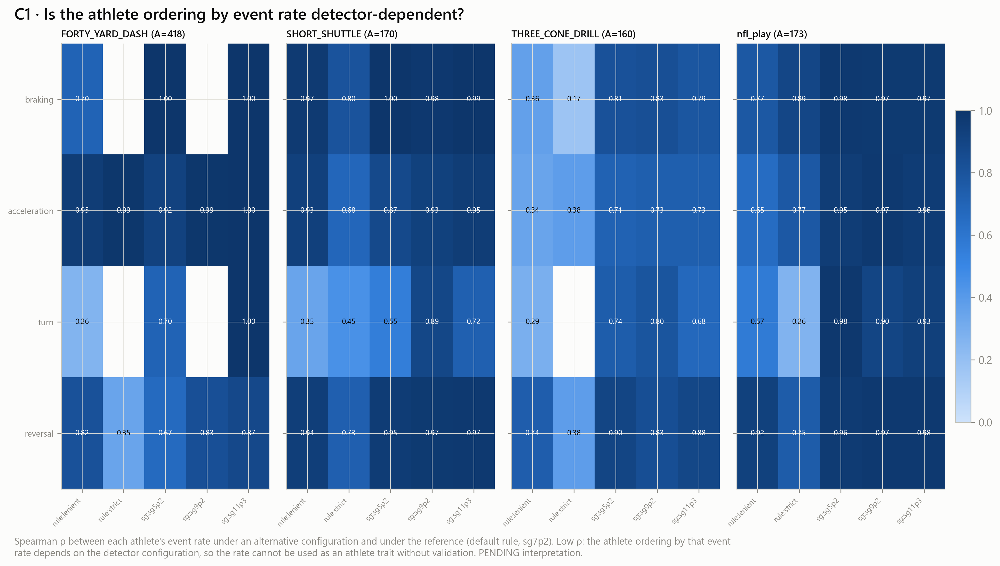

`reports/figures/phase_04/C1_event_sensitivity/C1_04_event_agreement.png`

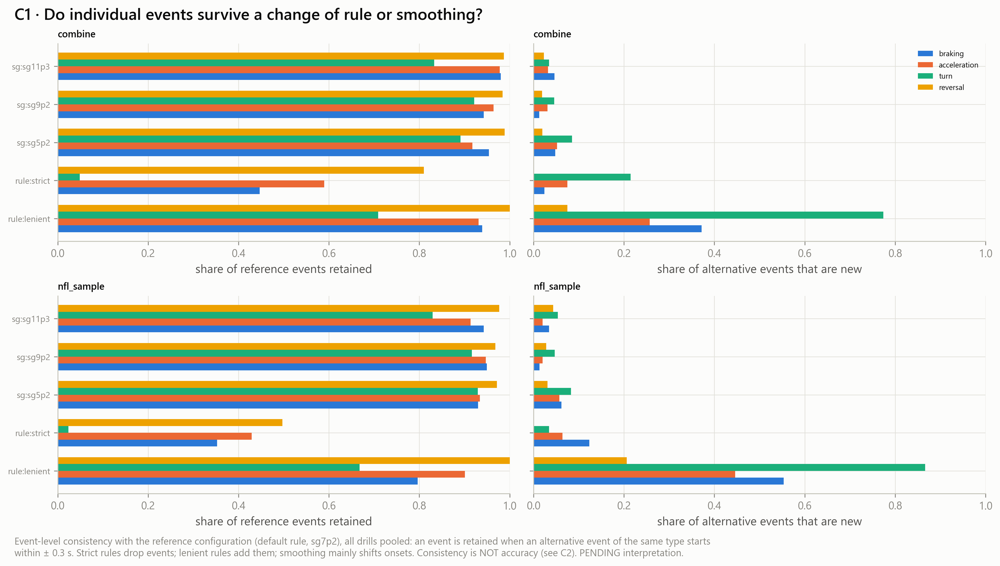

`reports/figures/phase_04/C1_event_sensitivity/C1_05_exposure_normalisation.png`

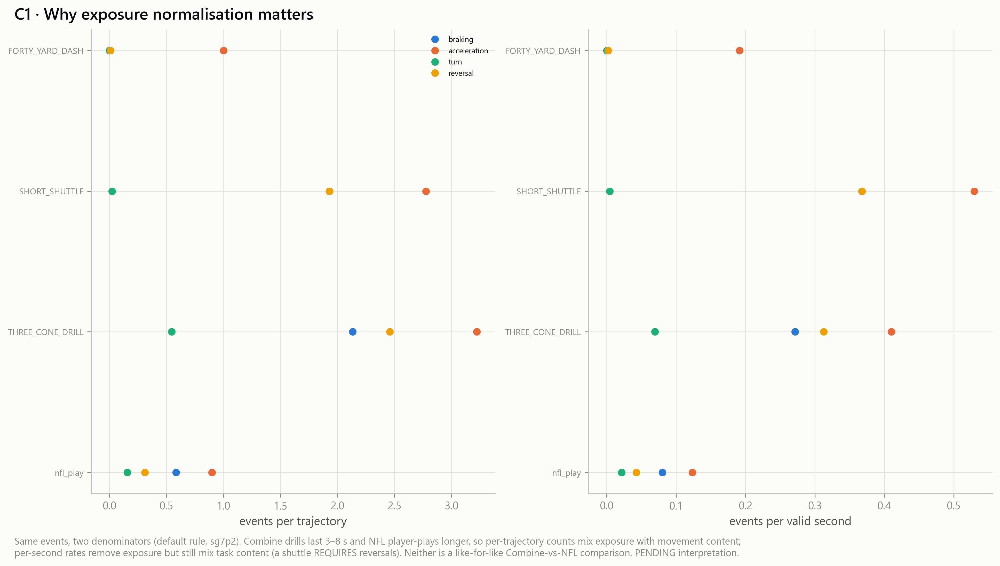

In [4]:
rates = table(c1.RATES)
if rates is not None:
    display(rates.filter((pl.col("drill") == "ALL") & (pl.col("smoothing") == "sg7p2"))
                 .pivot(on="rule", index=["domain", "event_type"], values="rate_per_s"))
stab = table(c1.STABILITY)
if stab is not None:
    display(stab.filter((pl.col("level") == "athlete") & (pl.col("drill") != "ALL")
                        & pl.col("drill").is_in(["SHORT_SHUTTLE", "THREE_CONE_DRILL", "nfl_play"]))
                .pivot(on="comparison", index=["drill", "event_type"], values="spearman_rate"))
figures("C1")

## C2 · Detector accuracy vs human labels (Study 1.3, validity)
Requires `--annotation-tasks`, manual labelling (`docs/PHASE_04_ANNOTATION_PROTOCOL.md`) and `--evaluate-annotations`.

In [5]:
s4_full = StudyStore(cfg, phase="phase_04")
cov = table(ad.COVERAGE, s4_full); display(cov)
perf = table(ad.PERFORMANCE, s4_full)
if perf is not None:
    display(perf.filter((pl.col("split") == "eval") & (pl.col("selection_set") == "random") & (pl.col("facet") == "all")
                        & (pl.col("label_set") == "all_labels") & (pl.col("tolerance_s") == 0.3)
                        & (pl.col("smoothing") == "sg7p2"))
                .select("detector_rule", "event_class", "n_tasks", "tp", "fp", "fn", "precision", "recall", "f1",
                        "f1_lower", "f1_upper", "onset_mae_s"))
d = s4_full.figure_dir("C2")
for p in sorted(d.glob("*.png")) if d.is_dir() else []:
    display(Image(filename=str(p), width=1000))

**missing:** reports/tables/phase_04/hypothesis_screening/C2_label_coverage.parquet missing — run the study that produces C2_label_coverage

None

**missing:** reports/tables/phase_04/hypothesis_screening/C2_detector_performance.parquet missing — run the study that produces C2_detector_performance

## V · Milestone 1 decision — feature status registry
Rule-based **proposal** from saved evidence; cut-offs in `reports/tables/phase_04/descriptive/P04_thresholds.csv`.

feature,combine,nfl_sample
str,str,str
"""n_acceleration""","""REJECTED""","""REJECTED"""
"""n_braking""","""REJECTED""","""PROVISIONAL"""
"""n_reversal""","""REJECTED""","""PROVISIONAL"""
"""n_turn""","""REJECTED""","""REJECTED"""
"""p90_abs_yaw_rate""","""EXPERIMENTAL""","""PROVISIONAL"""
"""p95_a_tan""","""REJECTED""","""PROVISIONAL"""
"""p95_decel""","""REJECTED""","""PROVISIONAL"""
"""p95_speed""","""EXPERIMENTAL""","""PROVISIONAL"""
"""path_smooth_yds""","""EXPERIMENTAL""","""PROVISIONAL"""


domain,feature,status,limiting_criteria
str,str,str,str
"""combine""","""n_acceleration""","""REJECTED""","""detector_f1, event_smoothing, …"
"""combine""","""n_braking""","""REJECTED""","""detector_f1, event_smoothing, …"
"""combine""","""n_reversal""","""REJECTED""","""detector_f1, event_smoothing, …"
"""combine""","""n_turn""","""REJECTED""","""detector_f1, event_smoothing, …"
"""combine""","""p90_abs_yaw_rate""","""EXPERIMENTAL""","""icc_setting_range, repeatabili…"
"""combine""","""p95_a_tan""","""REJECTED""","""icc_setting_range, repeatabili…"
"""combine""","""p95_decel""","""REJECTED""","""icc_setting_range, repeatabili…"
"""combine""","""p95_speed""","""EXPERIMENTAL""","""icc_setting_range, repeatabili…"
"""combine""","""path_smooth_yds""","""EXPERIMENTAL""","""repeatability"""


`reports/figures/phase_04/V_feature_validation/V_01_feature_status_matrix.png`

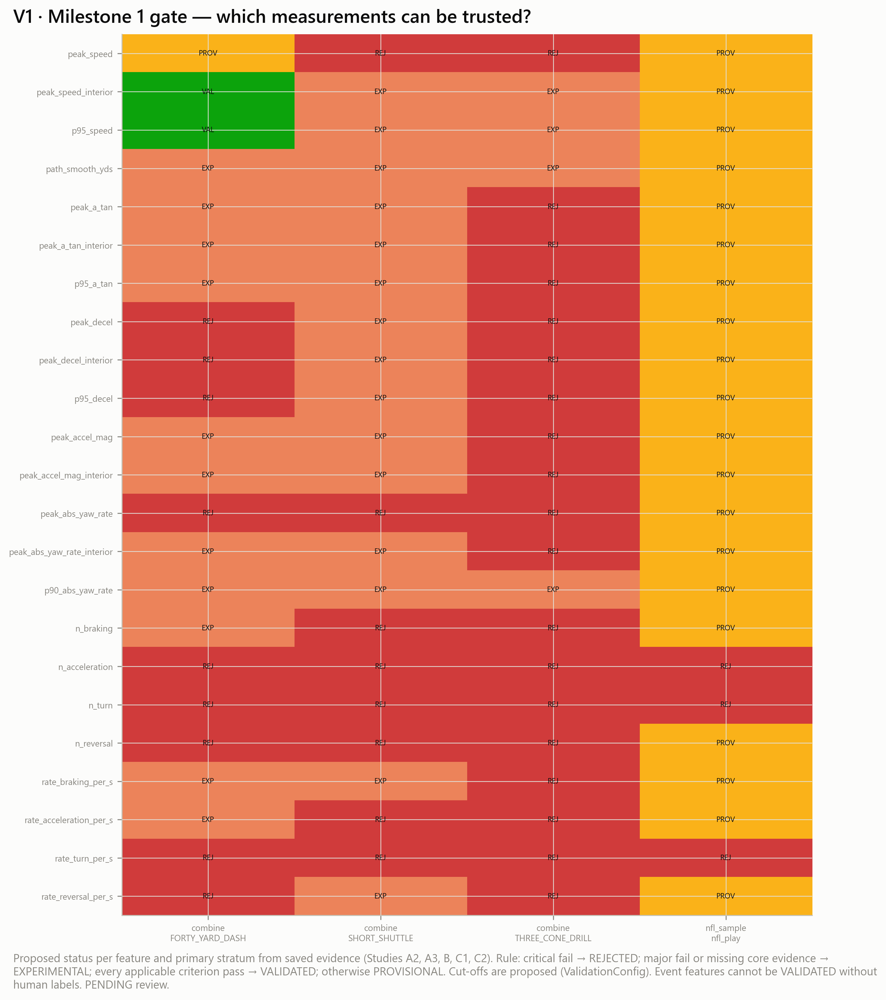

`reports/figures/phase_04/V_feature_validation/V_02_criterion_states.png`

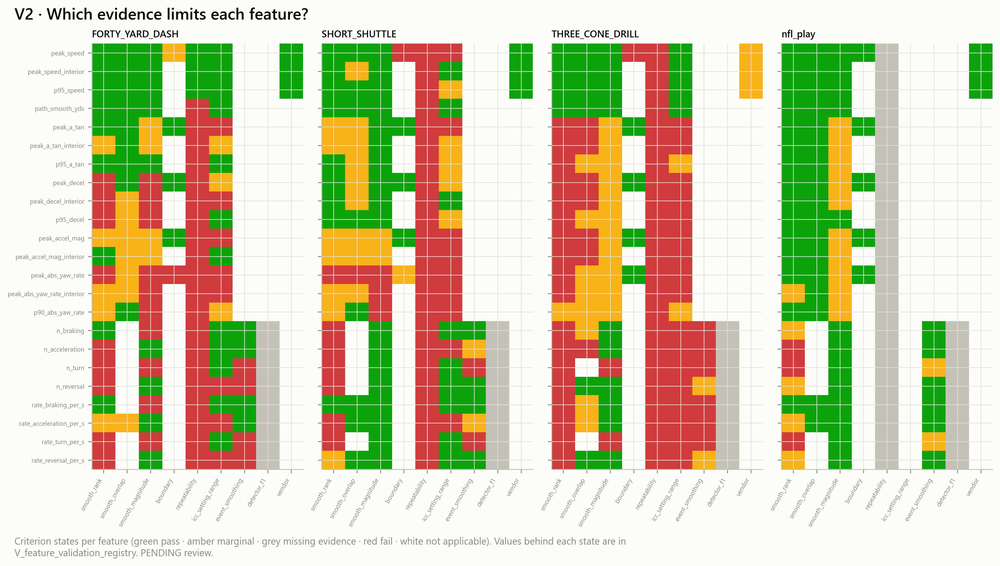

In [6]:
summ = table(v.SUMMARY)
if summ is not None:
    display(summ.pivot(on="domain", index="feature", values="status"))
    display(summ.select("domain", "feature", "status", "limiting_criteria"))
figures("V")

**Milestone 1 decision (after review):** _list the VALIDATED / PROVISIONAL features admitted to the Milestone 2 feature store, the REJECTED ones and why, and any proposed cut-off changes (with justification, never to rebalance statuses)._